# 05 Figures

*This notebook finishes **Step 6 (Experiments)** by turning the results from notebook 04 into the final figures used in the README.*

All figures share one style and a colour-blind-safe palette, and are saved to `figures/`.

## Setup

Shared style, then rebuilds the DLS par score at every ball using the same method as notebook 04.

In [9]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# one consistent style for every figure
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "lines.linewidth": 2,
})
os.makedirs("figures", exist_ok=True)

# rebuild the par score at every ball (same method as notebook 04)
table = pd.read_csv("reference/dls_standard_edition.csv").sort_values("overs_left")

def resources_left(balls_left, wickets):
    overs_left = np.asarray(balls_left) / 6
    wickets = np.asarray(wickets)
    out = np.zeros(len(overs_left))
    for w in range(10):
        m = wickets == w
        out[m] = np.interp(overs_left[m], table["overs_left"], table[f"w{w}"])
    return out

R1 = resources_left([120], [0])[0]

df = pd.read_csv("data/chases.csv")
df["par"] = (df["target"] - 1) * (R1 - resources_left(df["balls_left"], df["wickets"])) / R1
df["margin"] = df["runs"] - df["par"]

normal = df[~df["dls"]]
normal = normal[normal.groupby("match_id")["balls_left"].transform("max") >= 119]
s = normal[(normal["balls_left"] <= 90) & (normal["balls_left"] > 0) & (normal["wickets"] < 10)]
print(normal["match_id"].nunique(), "full chases")

4493 full chases


## Figure 1: the main finding

Win rate at DLS par by wickets lost, split by stage of the chase. This is the phase table from notebook 04 as a chart. Groups with fewer than 100 matches are left out because their error bars are too wide to say anything.

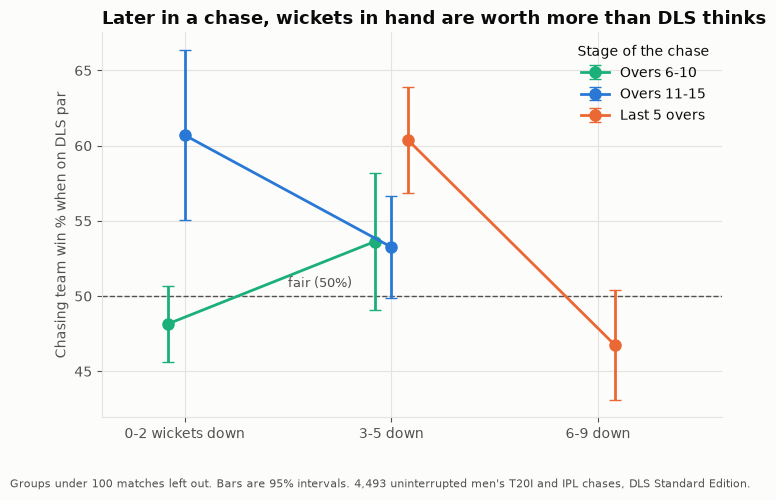

,phase,wkt_group,n,p,ci
1,Last 5 overs,3-5,732,0.604,0.035
2,Last 5 overs,6-9,712,0.468,0.037
3,Overs 11-15,0-2,285,0.607,0.057
4,Overs 11-15,3-5,828,0.533,0.034
6,Overs 6-10,0-2,1493,0.482,0.025
7,Overs 6-10,3-5,455,0.536,0.046


In [10]:
# moments on par (within 2 runs), each match once per wickets lost
first = (s[s["margin"].abs() <= 2]
         .sort_values("balls_left", ascending=False)
         .drop_duplicates(["match_id", "wickets"]).copy())
first["phase"] = pd.cut(first["balls_left"], [0, 30, 60, 90],
                        labels=["Last 5 overs", "Overs 11-15", "Overs 6-10"])
first["wkt_group"] = pd.cut(first["wickets"], [-1, 2, 5, 9],
                            labels=["0-2", "3-5", "6-9"])

g = first.groupby(["phase", "wkt_group"], observed=True)["won"].agg(n="count", p="mean").reset_index()
g["ci"] = 1.96 * np.sqrt(g["p"] * (1 - g["p"]) / g["n"])
g = g[g["n"] >= 100]          # drop groups too small to say anything

fig, ax = plt.subplots(figsize=(8, 5))
ax.axhline(50, ls="--", color=MUTED, lw=1)
ax.text(0.5, 50.6, "fair (50%)", color=MUTED, fontsize=9)

x = {"0-2": 0, "3-5": 1, "6-9": 2}
for phase, colour, nudge in [("Overs 6-10", AQUA, -0.08), ("Overs 11-15", BLUE, 0), ("Last 5 overs", ORANGE, 0.08)]:
    d = g[g["phase"] == phase]
    xs = d["wkt_group"].map(x).astype(float) + nudge
    ax.errorbar(xs, d["p"] * 100, yerr=d["ci"] * 100, fmt="o-", color=colour,
                ms=8, capsize=4, label=phase)

ax.set_xticks([0, 1, 2], ["0-2 wickets down", "3-5 down", "6-9 down"])
ax.set_xlim(-0.4, 2.6)
ax.set_ylabel("Chasing team win % when on DLS par")
ax.set_title("Later in a chase, wickets in hand are worth more than DLS thinks")
ax.legend(loc="upper right", frameon=False, title="Stage of the chase")
fig.text(0.01, -0.03, "Groups under 100 matches left out. Bars are 95% intervals. "
         "4,493 uninterrupted men's T20I and IPL chases, DLS Standard Edition.",
         color=MUTED, fontsize=8)
plt.savefig("figures/win_at_par_by_phase.png", dpi=200, bbox_inches="tight")
plt.show()
g.round(3)

## Figure 2: DLS ranks teams correctly

Win rate against runs ahead of or behind par. If DLS works at all, this should rise steadily and cross 50% close to par.

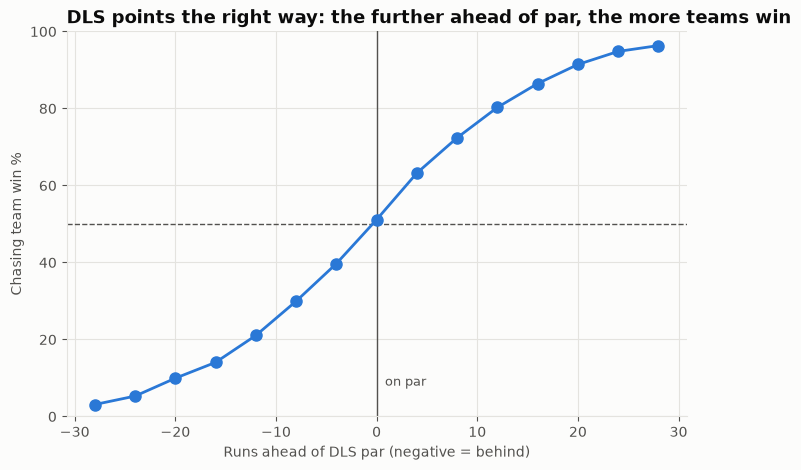

In [11]:
bins = np.arange(-30, 32, 4)
sc = s.assign(bin=pd.cut(s["margin"], bins)).drop_duplicates(["match_id", "bin"])
curve = sc.groupby("bin", observed=True)["won"].agg(n="count", p="mean")
mid = [b.mid for b in curve.index]

fig, ax = plt.subplots(figsize=(8, 5))
ax.axhline(50, ls="--", color=MUTED, lw=1)
ax.axvline(0, color=MUTED, lw=1)
ax.plot(mid, curve["p"] * 100, "o-", color=BLUE, ms=8)
ax.annotate("on par", (0, 8), xytext=(6, 0), textcoords="offset points", color=MUTED, fontsize=9)
ax.set_xlabel("Runs ahead of DLS par (negative = behind)")
ax.set_ylabel("Chasing team win %")
ax.set_ylim(0, 100)
ax.set_title("DLS points the right way: the further ahead of par, the more teams win")
plt.savefig("figures/win_vs_margin.png", dpi=200, bbox_inches="tight")
plt.show()

## Figure 3: a real example

The 2024 T20 World Cup final. South Africa needed 30 off 30 balls with 6 wickets in hand, then lost by 7 runs. The top panel shows the model's win probability through the chase. The bottom shows how far ahead of DLS par they were: if rain had ended the match at any point in the green area, South Africa would have won.

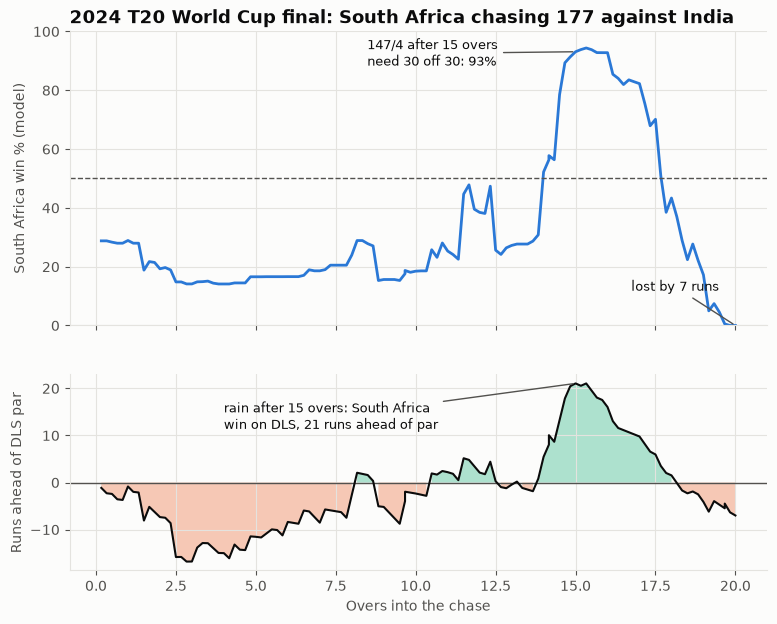

In [12]:
gbm = joblib.load("models/gbm.joblib")
features = ["runs_needed", "balls_left", "wickets_left", "rrr", "is_ipl"]

m = df[df["match_id"] == 1415755].copy()          # 2024 T20 World Cup final
m["wickets_left"] = 10 - m["wickets"]
m["rrr"] = m["runs_needed"] / np.maximum(m["balls_left"], 1) * 6
m["is_ipl"] = 0
m["win_prob"] = gbm.predict_proba(m[features])[:, 1] * 100
m["over"] = (120 - m["balls_left"]) / 6

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 2]})

top.plot(m["over"], m["win_prob"], color=BLUE)
top.axhline(50, ls="--", color=MUTED, lw=1)
top.set_ylim(0, 100)
top.set_ylabel("South Africa win % (model)")
top.set_title("2024 T20 World Cup final: South Africa chasing 177 against India")

after15 = m[m["balls_left"] == 30].iloc[0]
top.annotate(f"147/4 after 15 overs\nneed 30 off 30: {after15['win_prob']:.0f}%",
             (15, after15["win_prob"]), xytext=(-150, -10), textcoords="offset points",
             arrowprops=dict(arrowstyle="-", color=MUTED), fontsize=9)
top.annotate("lost by 7 runs", (20, 0), xytext=(-75, 25), textcoords="offset points",
             arrowprops=dict(arrowstyle="-", color=MUTED), fontsize=9)

bottom.axhline(0, color=MUTED, lw=1)
bottom.fill_between(m["over"], m["margin"], 0, where=m["margin"] >= 0, color=AQUA, alpha=0.35, lw=0)
bottom.fill_between(m["over"], m["margin"], 0, where=m["margin"] < 0, color=ORANGE, alpha=0.35, lw=0)
bottom.plot(m["over"], m["margin"], color=INK, lw=1.5)
bottom.set_ylabel("Runs ahead of DLS par")
bottom.set_xlabel("Overs into the chase")
bottom.annotate(f"rain after 15 overs: South Africa\nwin on DLS, {after15['margin']:.0f} runs ahead of par",
                (15, after15["margin"]), xytext=(4, 14), textcoords="data",
                arrowprops=dict(arrowstyle="-", color=MUTED), fontsize=9, va="center")

plt.savefig("figures/final_2024.png", dpi=200, bbox_inches="tight")
plt.show()